# Laboratorium 2A - klasyczna detekcja znaków drogowych i sygnalizatorów

Zbiór danych: BDD100K (100K Images + Labels, format JSON z 2018 r. - jeden plik JSON na obraz).

Schemat działania:
1. Generowanie kandydatów: maski kolorów HSV, morfologia, składowe spójne, MSER oraz hipotezy obudowy sygnalizatora wokół świecących plam.
2. Filtrowanie kandydatów po położeniu w kadrze, rozmiarze i proporcjach (progi wyznaczone z danych treningowych).
3. Weryfikacja kandydatów klasyfikatorem na cechach HOG, histogramie barwy i geometrii ramki (osobno dla znaków i sygnalizatorów).
4. Regresja ramki: korekta położenia i rozmiaru ramki kandydata.
5. NMS i próg pewności dobrany na zbiorze walidacyjnym.
6. Rozpoznawanie koloru sygnalizatora: reguły HSV albo klasyfikator koloru (wybór na zbiorze walidacyjnym).

Uruchomienie: `uv sync`, następnie `uv run jupyter lab`. Dane powinny leżeć w katalogu `100k/` z podkatalogami `train/` i `val/` (pliki `.jpg` i `.json` razem).

## 0. Konfiguracja

Zbiór testowy BDD100K nie ma publicznych etykiet, dlatego jako zbiór testowy wykorzystano podzbiór oficjalnego `val`. Oficjalny `train` podzielono na rozłączne części: treningową i walidacyjną.

Wyniki czasochłonnych kroków (kandydaci, próbki treningowe) zapisywane są w katalogu `cache/`. Po zmianie generatora kandydatów lub cech należy ten katalog usunąć.

In [1]:
import itertools
import json
import os
import pickle
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm

DATA_ROOT = "100k"
IMG_DIR = {"train": os.path.join(DATA_ROOT, "train"), "val": os.path.join(DATA_ROOT, "val")}
LBL_DIR = IMG_DIR

N_TRAIN, N_VAL, N_TEST = 2000, 500, 500
SEED = 42
CACHE_DIR = "cache"

CLASSES = ["traffic_sign", "traffic_light"]
COLORS = ["red", "yellow", "green", "unknown"]
COLOR_MAP = {"red": "red", "yellow": "yellow", "green": "green", "none": "unknown"}

random.seed(SEED)
np.random.seed(SEED)
os.makedirs(CACHE_DIR, exist_ok=True)


def load_or_compute(name, compute, *args):
    """Wczytuje wynik z cache albo liczy go i zapisuje. Nazwa pliku zawiera rozmiary podziału."""
    path = os.path.join(CACHE_DIR, f"{name}_{N_TRAIN}_{N_VAL}_{N_TEST}_{SEED}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    result = compute(*args)
    with open(path, "wb") as f:
        pickle.dump(result, f)
    return result

## 1. Zadanie 1 - wczytanie danych i analiza zbioru

In [2]:
def load_label(path):
    """Ramki znaków i sygnalizatorów dla jednego obrazu."""
    with open(path) as f:
        d = json.load(f)
    boxes = []
    for obj in d["frames"][0]["objects"]:
        if obj["category"] not in ("traffic sign", "traffic light") or "box2d" not in obj:
            continue
        b = obj["box2d"]
        attr = obj.get("attributes", {})
        cls = obj["category"].replace(" ", "_")
        color = None
        if cls == "traffic_light":
            color = COLOR_MAP.get(attr.get("trafficLightColor", "none"), "unknown")
        boxes.append({
            "cls": cls,
            "box": [b["x1"], b["y1"], b["x2"], b["y2"]],
            "color": color,
            "occluded": attr.get("occluded", False),
            "truncated": attr.get("truncated", False),
        })
    return {"boxes": boxes, "attrs": d.get("attributes", {})}


def load_split(split, names):
    data = {}
    for name in names:
        lbl_path = os.path.join(LBL_DIR[split], name + ".json")
        img_path = os.path.join(IMG_DIR[split], name + ".jpg")
        if os.path.exists(lbl_path) and os.path.exists(img_path):
            item = load_label(lbl_path)
            item["img_path"] = img_path
            data[name] = item
    return data


def list_names(split):
    return sorted(f[:-5] for f in os.listdir(LBL_DIR[split]) if f.endswith(".json"))


rng = random.Random(SEED)
pool = rng.sample(list_names("train"), N_TRAIN + N_VAL)
train = load_split("train", pool[:N_TRAIN])
val = load_split("train", pool[N_TRAIN:])
test = load_split("val", rng.sample(list_names("val"), N_TEST))

SPLITS = {"train": train, "val": val, "test": test}
ALL = {**train, **val, **test}
print(f"train: {len(train)}, val: {len(val)}, test: {len(test)}")


def gt_boxes(item, cls):
    boxes = [b["box"] for b in item["boxes"] if b["cls"] == cls]
    return np.array(boxes, np.float32).reshape(-1, 4)


def gt_colors(item):
    return [b["color"] for b in item["boxes"] if b["cls"] == "traffic_light"]

train: 2000, val: 500, test: 500


### 1.1 Statystyki

In [3]:
rows = []
for split, data in SPLITS.items():
    for name, item in data.items():
        for b in item["boxes"]:
            x1, y1, x2, y2 = b["box"]
            rows.append({"split": split, "image": name, "cls": b["cls"], "color": b["color"],
                         "x1": x1, "y1": y1, "x2": x2, "y2": y2, "w": x2 - x1, "h": y2 - y1,
                         "occluded": b["occluded"], "truncated": b["truncated"], **item["attrs"]})
df = pd.DataFrame(rows)
df["size"] = np.sqrt(df.w.clip(lower=0) * df.h.clip(lower=0))

print("Liczba obiektów w klasach:")
display(df.groupby(["split", "cls"]).size().unstack(fill_value=0))
print("Kolory sygnalizatorów:")
display(df[df.cls == "traffic_light"].groupby(["split", "color"]).size().unstack(fill_value=0))
print("Rozmiar ramki sqrt(w*h) [px]:")
display(df.groupby("cls")["size"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

Liczba obiektów w klasach:


cls,traffic_light,traffic_sign
split,,
test,1421,1677
train,5332,6868
val,1344,1798


Kolory sygnalizatorów:


color,green,red,unknown,yellow
split,,,,
test,596,349,447,29
train,2329,1273,1601,129
val,544,344,440,16


Rozmiar ramki sqrt(w*h) [px]:


,count,mean,std,min,10%,25%,50%,75%,90%,max
cls,,,,,,,,,,
traffic_light,8097.0,19.758667,12.362302,0.0,9.711633,12.195112,16.584910,24.195272,33.641309,550.140264
traffic_sign,10343.0,27.573619,20.809192,0.0,11.839347,15.187489,21.400883,32.499542,49.282337,313.262909


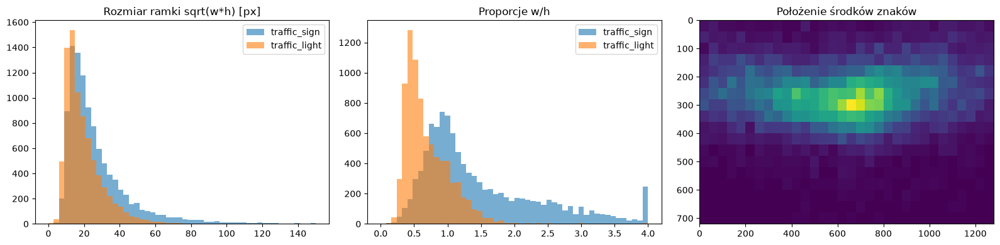

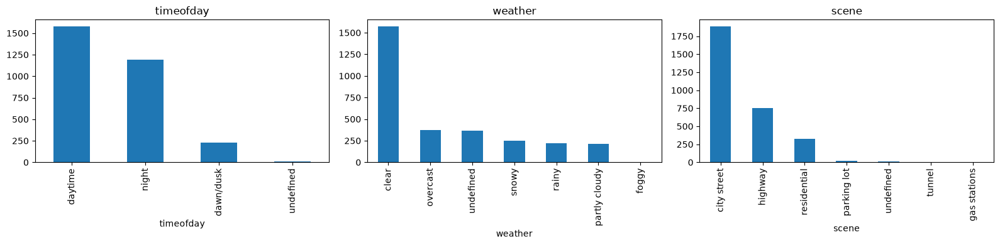

Obrazy bez żadnego znaku: 545 / 3000


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for cls in CLASSES:
    s = df[df.cls == cls]
    axes[0].hist(s["size"], bins=50, range=(0, 150), alpha=0.6, label=cls)
    axes[1].hist((s.w / s.h.clip(lower=1e-3)).clip(0, 4), bins=50, alpha=0.6, label=cls)
axes[0].set_title("Rozmiar ramki sqrt(w*h) [px]")
axes[0].legend()
axes[1].set_title("Proporcje w/h")
axes[1].legend()

signs = df[df.cls == "traffic_sign"]
axes[2].hist2d((signs.x1 + signs.x2) / 2, (signs.y1 + signs.y2) / 2, bins=[32, 18], range=[[0, 1280], [0, 720]])
axes[2].invert_yaxis()
axes[2].set_title("Położenie środków znaków")
plt.tight_layout()
plt.show()

img_attrs = pd.DataFrame([item["attrs"] for item in ALL.values()])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["timeofday", "weather", "scene"]):
    img_attrs[col].value_counts().plot.bar(ax=ax, title=col)
plt.tight_layout()
plt.show()

no_signs = sum(len(gt_boxes(item, "traffic_sign")) == 0 for item in ALL.values())
print(f"Obrazy bez żadnego znaku: {no_signs} / {len(ALL)}")

### 1.2 Wizualizacja ramek referencyjnych

Żółte ramki - znaki, ramki w kolorze światła - sygnalizatory (szare - kolor nieokreślony).

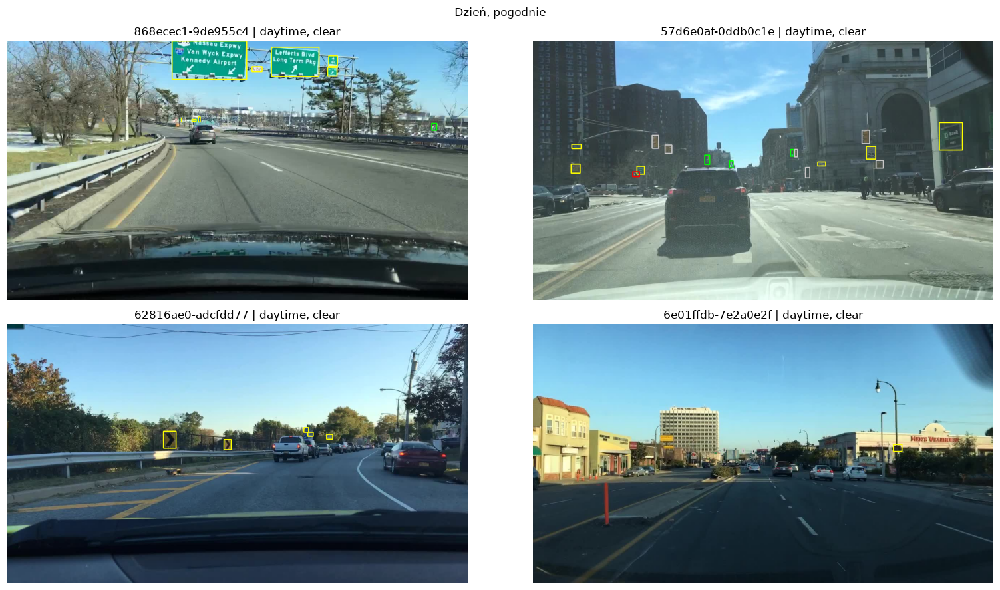

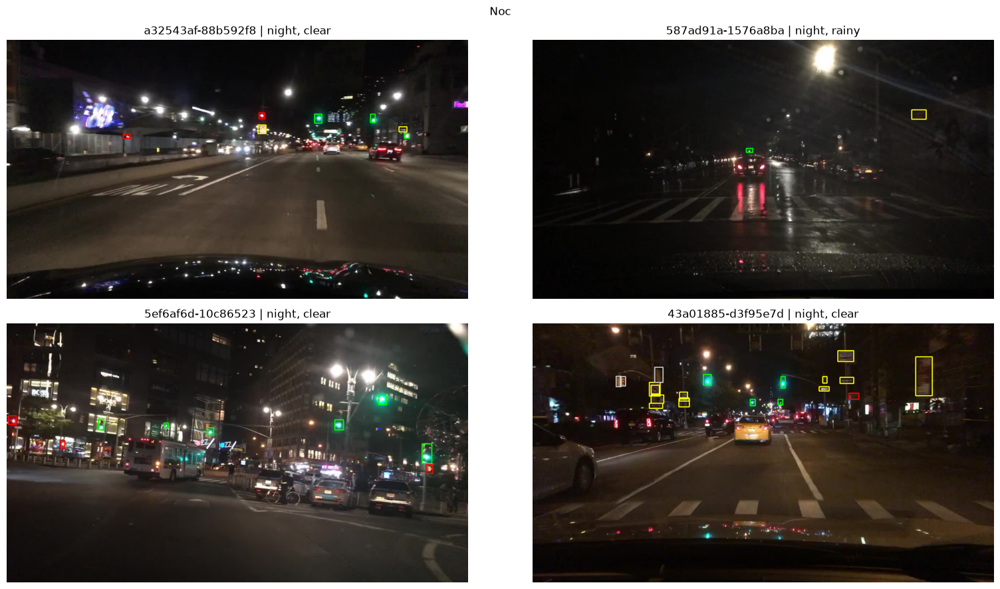

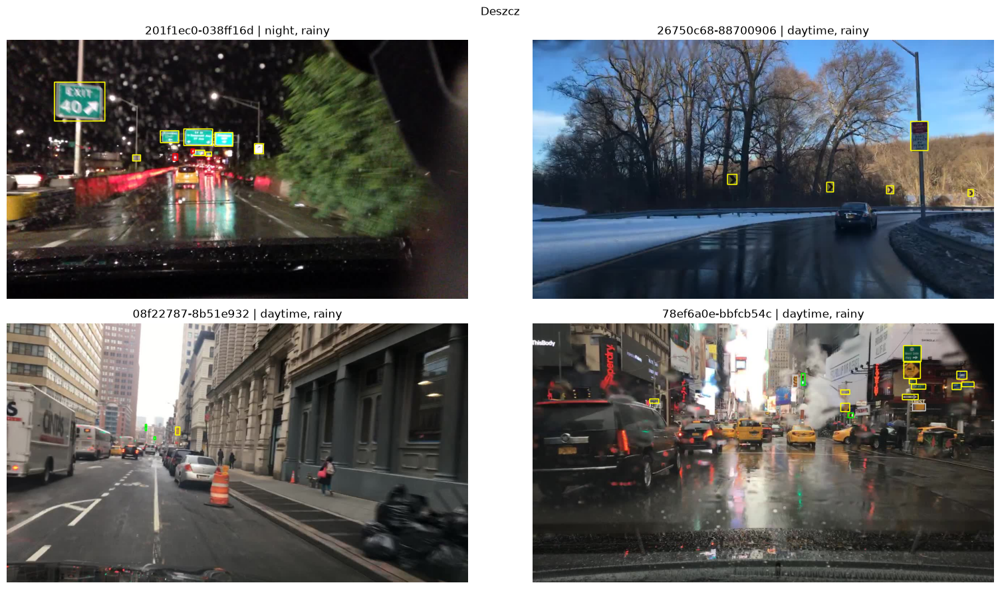

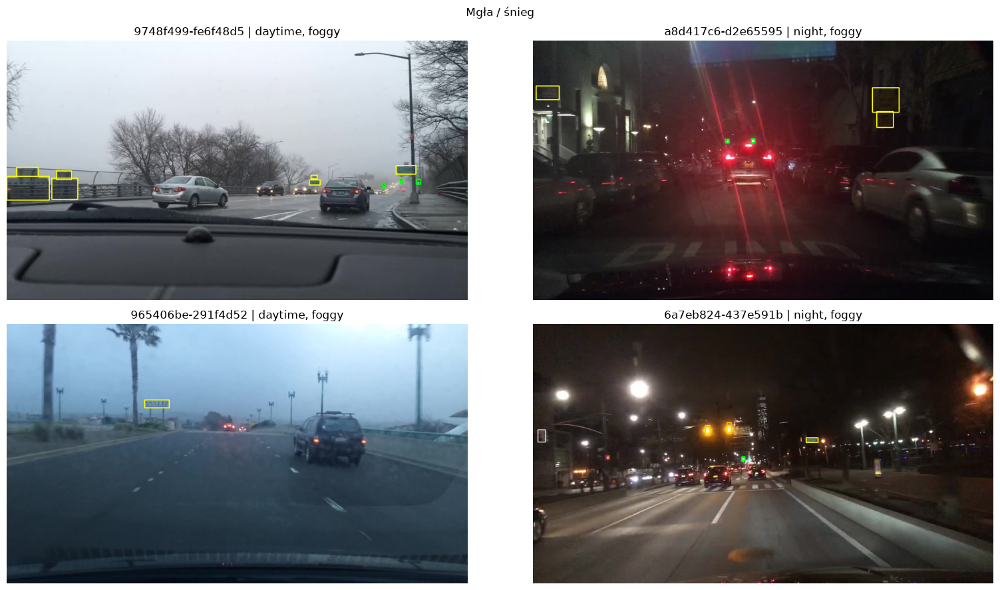

In [5]:
DRAW_COLORS = {"traffic_sign": (255, 255, 0), "red": (255, 0, 0), "yellow": (255, 200, 0),
               "green": (0, 255, 0), "unknown": (200, 200, 200)}


def read_rgb(name):
    return cv2.cvtColor(cv2.imread(ALL[name]["img_path"]), cv2.COLOR_BGR2RGB)


def draw_gt(img, item, thickness=2):
    img = img.copy()
    for b in item["boxes"]:
        x1, y1, x2, y2 = map(int, b["box"])
        key = b["color"] if b["cls"] == "traffic_light" else "traffic_sign"
        cv2.rectangle(img, (x1, y1), (x2, y2), DRAW_COLORS[key], thickness)
    return img


def show_examples(names, title, ncols=2):
    if not names:
        print("Brak obrazów:", title)
        return
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 4.5 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, name in zip(axes.ravel(), names):
        attrs = ALL[name]["attrs"]
        ax.imshow(draw_gt(read_rgb(name), ALL[name]))
        ax.set_title(f"{name} | {attrs.get('timeofday')}, {attrs.get('weather')}")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def pick(data, k=4, **conditions):
    """Losuje k obrazów z co najmniej jedną ramką, spełniających warunki na atrybutach."""
    names = [name for name, item in data.items()
             if item["boxes"] and all(item["attrs"].get(key) == value for key, value in conditions.items())]
    return random.sample(names, min(k, len(names)))


show_examples(pick(train, timeofday="daytime", weather="clear"), "Dzień, pogodnie")
show_examples(pick(train, timeofday="night"), "Noc")
show_examples(pick(train, weather="rainy"), "Deszcz")
show_examples(pick(train, weather="foggy") or pick(train, weather="snowy"), "Mgła / śnieg")

### 1.3 Kontrola jakości etykiet

In [6]:
resolutions = {}
for item in list(ALL.values())[:300]:
    h, w = cv2.imread(item["img_path"]).shape[:2]
    resolutions[(w, h)] = resolutions.get((w, h), 0) + 1
print("Rozdzielczości (pierwsze 300 obrazów):", resolutions)

W_IMG, H_IMG = 1280, 720
checks = {
    "ramka o zerowym/ujemnym rozmiarze": (df.w <= 0) | (df.h <= 0),
    "ramka poza obrazem": (df.x1 < 0) | (df.y1 < 0) | (df.x2 > W_IMG) | (df.y2 > H_IMG),
    "bardzo mała ramka (< 8 px)": df["size"] < 8,
    "zasłonięte (occluded)": df.occluded,
    "ucięte (truncated)": df.truncated,
    "duplikaty ramek": df.duplicated(subset=["image", "cls", "x1", "y1", "x2", "y2"]),
}
quality = pd.DataFrame({cls: {name: int((mask & (df.cls == cls)).sum()) for name, mask in checks.items()}
                        for cls in CLASSES})
display(quality)

Rozdzielczości (pierwsze 300 obrazów): {(1280, 720): 300}


,traffic_sign,traffic_light
ramka o zerowym/ujemnym rozmiarze,2,5
ramka poza obrazem,0,0
bardzo mała ramka (< 8 px),89,252
zasłonięte (occluded),1122,259
ucięte (truncated),299,215
duplikaty ramek,0,0


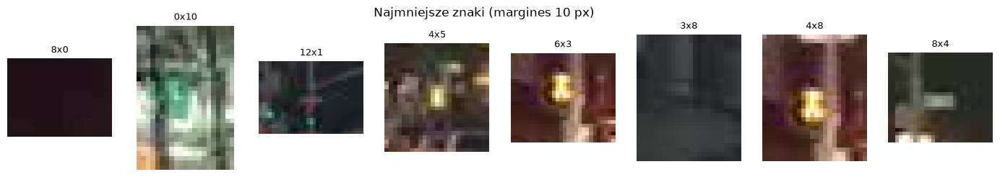

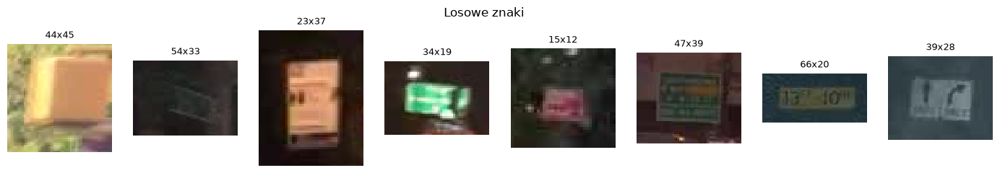

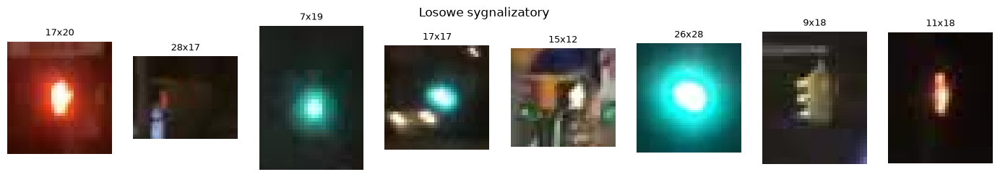

In [7]:
def show_crops(rows, title, pad=10):
    fig, axes = plt.subplots(1, len(rows), figsize=(2.2 * len(rows), 2.6), squeeze=False)
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        img = read_rgb(r.image)
        x1, y1 = int(r.x1), int(r.y1)
        x2, y2 = int(np.ceil(r.x2)), int(np.ceil(r.y2))
        ax.imshow(img[max(0, y1 - pad):y2 + pad, max(0, x1 - pad):x2 + pad], interpolation="nearest")
        ax.set_title(f"{r.w:.0f}x{r.h:.0f}", fontsize=9)
        ax.axis("off")
    plt.suptitle(title)
    plt.show()


train_df = df[df.split == "train"]
show_crops(train_df[train_df.cls == "traffic_sign"].nsmallest(8, "size"), "Najmniejsze znaki (margines 10 px)")
show_crops(train_df[train_df.cls == "traffic_sign"].sample(8, random_state=SEED), "Losowe znaki")
show_crops(train_df[train_df.cls == "traffic_light"].sample(8, random_state=SEED), "Losowe sygnalizatory")

### Wnioski z analizy

- W wybranych 3000 obrazach jest 10 343 znaków i 8 097 sygnalizatorów. Wszystkie sprawdzone obrazy mają rozdzielczość 1280×720.
- Większość obiektów jest mała. Mediana rozmiaru ramki to ok. 21 px dla znaków i 17 px dla sygnalizatorów, a co dziesiąty obiekt ma mniej niż 10-12 px.
- Kolory sygnalizatorów nie są zbalansowane. Najwięcej jest zielonych, a żółtych tylko ok. 2%. Kolor `unknown` (ok. 30%) oznacza, że koloru nie oznaczono, a nie że sygnalizator jest wyłączony.
- Znaki i sygnalizatory są prawie zawsze w górnej i środkowej części obrazu. Im bliżej horyzontu, tym są mniejsze.
- W etykietach znaleziono kilka ramek o zerowym rozmiarze (7), dużo bardzo małych obiektów (poniżej 8 px: 89 znaków i 252 sygnalizatory) oraz wiele obiektów zasłoniętych lub uciętych przez krawędź obrazu.
- Do klasy `traffic_sign` należą też tyły znaków, tablice z nazwami ulic i tablice informacyjne, więc obiekty w tej klasie bardzo się od siebie różnią.
- Ramek w zbiorze testowym nie zmieniano, zostały w nim także ramki o zerowym rozmiarze.

## 2. Ograniczenie obszaru i rozmiaru

Znaki i sygnalizatory praktycznie nie występują w dolnej części kadru (droga, maska samochodu), a ich rozmiar i proporcje mieszczą się w ograniczonym przedziale. Progi wyznaczono z percentyli zbioru treningowego, osobno dla każdej klasy. Odcięcie dołu liczone jest po dolnej krawędzi ramki (`y2`). Do progów rozmiaru i proporcji dodano margines, ponieważ ramki kandydatów są mniej dokładne niż ramki GT.

In [8]:
Q = 0.02        # odsetek obiektów odcinanych z każdej strony rozkładu
MARGIN = 0.2


def compute_thresholds(cls):
    s = df[(df.split == "train") & (df.cls == cls) & (df.w > 0) & (df.h > 0)]
    aspect = s.w / s.h
    return {
        "y_max": s.y2.quantile(1 - Q),
        "size_min": max(s["size"].quantile(Q), 4.0),
        "size_max": s["size"].quantile(1 - Q) * (1 + MARGIN),
        "ar_min": aspect.quantile(Q) * (1 - MARGIN),
        "ar_max": aspect.quantile(1 - Q) * (1 + MARGIN),
    }


FILTERS = {cls: compute_thresholds(cls) for cls in CLASSES}
display(pd.DataFrame(FILTERS).round(2))


def filter_mask(boxes, f):
    """True dla ramek spełniających progi położenia, rozmiaru i proporcji."""
    boxes = np.asarray(boxes, np.float32).reshape(-1, 4)
    w = boxes[:, 2] - boxes[:, 0]
    h = boxes[:, 3] - boxes[:, 1]
    size = np.sqrt(np.clip(w * h, 0, None))
    aspect = w / np.maximum(h, 1e-3)
    return ((boxes[:, 3] <= f["y_max"])
            & (size >= f["size_min"]) & (size <= f["size_max"])
            & (aspect >= f["ar_min"]) & (aspect <= f["ar_max"]))


for cls in CLASSES:
    G = np.concatenate([gt_boxes(item, cls) for item in val.values()])
    print(f"{cls}: po filtrach zostaje {filter_mask(G, FILTERS[cls]).mean():.1%} obiektów GT (val)")

,traffic_sign,traffic_light
y_max,479.61,467.35
size_min,9.09,7.39
size_max,108.49,59.35
ar_min,0.34,0.23
ar_max,4.80,1.88


traffic_sign: po filtrach zostaje 93.9% obiektów GT (val)
traffic_light: po filtrach zostaje 94.7% obiektów GT (val)


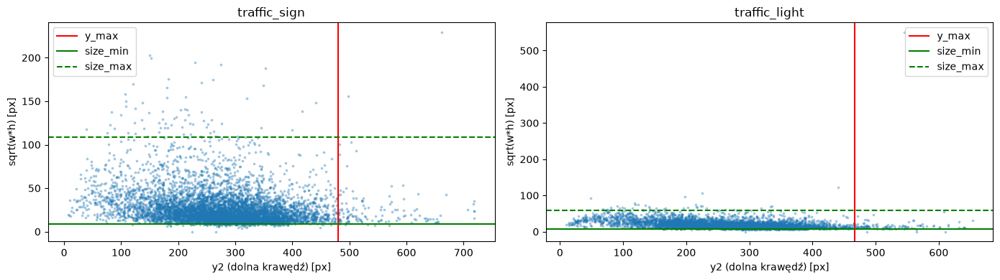

Rozmiar znaków w pasach wysokości obrazu (percentyle 5, 50, 95):


,0.05,0.50,0.95
pas,,,
"(0, 240]",12.0,26.9,82.1
"(240, 360]",10.0,19.3,50.8
"(360, 480]",9.8,18.0,47.1
"(480, 720]",9.8,17.5,40.3


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, cls in zip(axes, CLASSES):
    s = df[(df.split == "train") & (df.cls == cls)]
    f = FILTERS[cls]
    ax.scatter(s.y2, s["size"], s=3, alpha=0.3)
    ax.axvline(f["y_max"], color="r", label="y_max")
    ax.axhline(f["size_min"], color="g", label="size_min")
    ax.axhline(f["size_max"], color="g", ls="--", label="size_max")
    ax.set_xlabel("y2 (dolna krawędź) [px]")
    ax.set_ylabel("sqrt(w*h) [px]")
    ax.set_title(cls)
    ax.legend()
plt.tight_layout()
plt.show()

signs = df[(df.split == "train") & (df.cls == "traffic_sign")].copy()
signs["pas"] = pd.cut((signs.y1 + signs.y2) / 2, bins=[0, 240, 360, 480, 720])
print("Rozmiar znaków w pasach wysokości obrazu (percentyle 5, 50, 95):")
display(signs.groupby("pas", observed=True)["size"].quantile([0.05, 0.5, 0.95]).unstack().round(1))

## 3. Metryki

Predykcja jest prawdziwie pozytywna (TP), jeżeli jej IoU z niewykorzystaną ramką GT tej samej klasy wynosi co najmniej 0,5. Predykcje dopasowywane są w kolejności malejącej pewności. Kolor oceniany jest tylko dla poprawnie zlokalizowanych sygnalizatorów.

In [10]:
METRICS = ["TP", "FP", "FN", "precision", "recall", "F1"]


def iou_matrix(a, b):
    a = np.asarray(a, np.float32).reshape(-1, 4)
    b = np.asarray(b, np.float32).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), np.float32)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def nms(boxes, scores, iou_thr):
    """Indeksy ramek zachowanych po non-maximum suppression."""
    if len(boxes) == 0:
        return np.zeros(0, int)
    xywh = np.c_[boxes[:, :2], boxes[:, 2:] - boxes[:, :2]].tolist()
    scores = np.asarray(scores, float)
    scores = scores - scores.min() + 1.0     # NMSBoxes wymaga dodatnich wyników
    keep = cv2.dnn.NMSBoxes(xywh, scores.tolist(), 0.0, iou_thr)
    return np.array(keep, dtype=int).reshape(-1)


def match(pred_boxes, pred_scores, gt, iou_thr=0.5):
    """Zwraca: czy predykcja jest TP, indeks dopasowanej ramki GT, czy ramka GT została wykryta."""
    is_tp = np.zeros(len(pred_boxes), bool)
    matched_gt = -np.ones(len(pred_boxes), int)
    gt_used = np.zeros(len(gt), bool)
    if len(pred_boxes) == 0 or len(gt) == 0:
        return is_tp, matched_gt, gt_used
    ious = iou_matrix(pred_boxes, gt)
    for i in np.argsort(-np.asarray(pred_scores)):
        candidates = ious[i].copy()
        candidates[gt_used] = -1
        j = int(np.argmax(candidates))
        if candidates[j] >= iou_thr:
            is_tp[i] = True
            matched_gt[i] = j
            gt_used[j] = True
    return is_tp, matched_gt, gt_used


def empty_prediction():
    return {"boxes": np.zeros((0, 4), np.float32), "scores": np.zeros(0)}


def evaluate(preds, data, cls, iou_thr=0.5):
    """preds: {obraz: {"boxes", "scores", opcjonalnie "colors"}}. Zwraca metryki i listy błędów."""
    tp = fp = fn = 0
    false_pos, false_neg, gt_rows, color_pairs = [], [], [], []
    for name, item in data.items():
        gt = gt_boxes(item, cls)
        pred = preds.get(name, empty_prediction())
        boxes = np.asarray(pred["boxes"]).reshape(-1, 4)
        scores = np.asarray(pred["scores"])
        is_tp, matched_gt, gt_used = match(boxes, scores, gt, iou_thr)

        tp += is_tp.sum()
        fp += (~is_tp).sum()
        fn += (~gt_used).sum()
        for i in np.where(~is_tp)[0]:
            false_pos.append((name, boxes[i], scores[i]))
        for j in np.where(~gt_used)[0]:
            false_neg.append((name, gt[j]))
        for j, g in enumerate(gt):
            size = np.sqrt(max((g[2] - g[0]) * (g[3] - g[1]), 0))
            gt_rows.append({"image": name, "size": size, "timeofday": item["attrs"].get("timeofday"),
                            "found": gt_used[j]})
        if "colors" in pred:
            colors_gt = gt_colors(item)
            for i in np.where(is_tp)[0]:
                color_pairs.append((colors_gt[matched_gt[i]], pred["colors"][i]))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"TP": int(tp), "FP": int(fp), "FN": int(fn), "precision": precision, "recall": recall, "F1": f1,
            "fp": false_pos, "fn": false_neg, "gt": pd.DataFrame(gt_rows), "colors": color_pairs}

## 4. Generowanie kandydatów

**Znaki:** maski HSV dla kolorów czerwonego (dwa zakresy barwy), niebieskiego i żółtego, następnie otwarcie i domknięcie morfologiczne oraz składowe spójne. Dodatkowo MSER, który znajduje jednolite, kontrastowe regiony niezależnie od koloru (białe tablice, tyły znaków). MSER uruchamiany jest na obrazie w skali szarości oraz na kanałach V (jasność) i S (nasycenie), ponieważ część znaków słabo odcina się od tła w skali szarości, a wyraźnie w nasyceniu. MSER często obejmuje tylko wnętrze znaku, dlatego dodano kopie ramek powiększone 1,2 raza.

**Sygnalizatory:** jasne i nasycone plamy w zakresach barwy czerwonej, żółtej i zielonej (świecąca lampa). Wokół każdej plamy tworzone są hipotezy obudowy 3-komorowej: lampa u góry, w środku lub na dole, orientacja pionowa lub pozioma. Dodatkowo regiony MSER ze skali szarości (ciemne obudowy).

In [11]:
MSER = cv2.MSER_create(5, 15, 25000)     # delta, min_area, max_area
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))


def clean_mask(mask):
    m = mask.astype(np.uint8) * 255
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, KERNEL)
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, KERNEL, iterations=2)


def component_boxes(mask, min_area):
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    stats = stats[1:]                              # pomijamy tło
    stats = stats[stats[:, 4] >= min_area]
    x, y, w, h = stats[:, 0], stats[:, 1], stats[:, 2], stats[:, 3]
    return np.c_[x, y, x + w, y + h].astype(np.float32)


def scale_boxes(boxes, factor):
    cx = (boxes[:, 0] + boxes[:, 2]) / 2
    cy = (boxes[:, 1] + boxes[:, 3]) / 2
    half_w = (boxes[:, 2] - boxes[:, 0]) * factor / 2
    half_h = (boxes[:, 3] - boxes[:, 1]) * factor / 2
    return np.c_[cx - half_w, cy - half_h, cx + half_w, cy + half_h].astype(np.float32)


def housing_hypotheses(lamps):
    """Dla plamy lampy o średnicy d: możliwe ramki obudowy o szerokości k*d i wysokości 2,7 szerokości."""
    boxes = []
    for x1, y1, x2, y2 in lamps:
        d = max(x2 - x1, y2 - y1)
        if d < 2 or d > 40:
            continue
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        for k in (1.3, 1.8):
            width = k * d
            length = 2.7 * width
            for lamp_pos in (1 / 6, 1 / 2, 5 / 6):          # lampa u góry, w środku, na dole
                top = cy - lamp_pos * length
                boxes.append([cx - width / 2, top, cx + width / 2, top + length])        # pionowo
                left = cx - lamp_pos * length
                boxes.append([left, cy - width / 2, left + length, cy + width / 2])      # poziomo
    return np.array(boxes, np.float32).reshape(-1, 4)


def clip_and_deduplicate(boxes, shape, min_side=3, max_side=400):
    """Przycina ramki do obrazu, odrzuca skrajne rozmiary i prawie identyczne ramki."""
    H, W = shape[:2]
    boxes = np.asarray(boxes, np.float32).reshape(-1, 4).copy()
    boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, W - 1)
    boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, H - 1)
    w = boxes[:, 2] - boxes[:, 0]
    h = boxes[:, 3] - boxes[:, 1]
    boxes = boxes[(w >= min_side) & (h >= min_side) & (w <= max_side) & (h <= max_side)]
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return boxes[nms(boxes, areas, 0.8)]


def mser_boxes(channel):
    _, xywh = MSER.detectRegions(channel)
    xywh = np.asarray(xywh, np.float32).reshape(-1, 4)
    return np.c_[xywh[:, :2], xywh[:, :2] + xywh[:, 2:]]


def generate_candidates(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h = hsv[..., 0].astype(int)
    s = hsv[..., 1].astype(int)
    v = hsv[..., 2].astype(int)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    mser_gray = mser_boxes(gray)
    mser = np.concatenate([mser_gray, mser_boxes(hsv[..., 2]), mser_boxes(hsv[..., 1])])

    sign_masks = {
        "red": ((h < 10) | (h >= 160)) & (s > 90) & (v > 60),
        "blue": (h >= 95) & (h <= 130) & (s > 90) & (v > 50),
        "yellow": (h >= 15) & (h <= 35) & (s > 90) & (v > 80),
    }
    sign_boxes = [component_boxes(clean_mask(m), 10) for m in sign_masks.values()]
    sign_boxes += [mser, scale_boxes(mser, 1.2)]

    bright = (v >= 170) & (s >= 60)
    lamp_masks = {
        "red": bright & ((h < 12) | (h >= 160)),
        "yellow": bright & (h >= 12) & (h < 35),
        "green": bright & (h >= 40) & (h <= 100),
    }
    lamps = [component_boxes(cv2.dilate(m.astype(np.uint8) * 255, KERNEL), 2) for m in lamp_masks.values()]
    light_boxes = [housing_hypotheses(np.concatenate(lamps)), mser_gray]

    return {
        "traffic_sign": clip_and_deduplicate(np.concatenate(sign_boxes), img.shape),
        "traffic_light": clip_and_deduplicate(np.concatenate(light_boxes), img.shape),
    }


def compute_candidates(data):
    return {name: generate_candidates(cv2.imread(item["img_path"]))
            for name, item in tqdm(data.items(), desc="kandydaci")}


CANDS = {}
for split, data in SPLITS.items():
    CANDS[split] = load_or_compute(f"cands_{split}", compute_candidates, data)

kandydaci:   0%|          | 0/2000 [00:00<?, ?it/s]

kandydaci:   0%|          | 0/500 [00:00<?, ?it/s]

kandydaci:   0%|          | 0/500 [00:00<?, ?it/s]

### 4.1 Recall propozycji

Obiekt może zostać wykryty tylko wtedy, gdy któryś kandydat pokrywa go z IoU ≥ 0,5. Recall propozycji jest więc górną granicą recallu całego detektora.

In [12]:
def proposal_stats(data, cands, cls, use_filter):
    hits = total = n_cands = 0
    for name, item in data.items():
        gt = gt_boxes(item, cls)
        boxes = cands[name][cls]
        if use_filter:
            boxes = boxes[filter_mask(boxes, FILTERS[cls])]
        n_cands += len(boxes)
        total += len(gt)
        if len(gt) and len(boxes):
            hits += int((iou_matrix(gt, boxes).max(1) >= 0.5).sum())
    return {"kandydaci / obraz": n_cands / len(data), "recall propozycji": hits / max(total, 1)}


rows = {}
for cls in CLASSES:
    rows[(cls, "bez filtrów")] = proposal_stats(val, CANDS["val"], cls, use_filter=False)
    rows[(cls, "z filtrami")] = proposal_stats(val, CANDS["val"], cls, use_filter=True)
display(pd.DataFrame(rows).T.round(3))

kandydaci / obraz  recall propozycji
traffic_sign  bez filtrów           3743.810              0.655
              z filtrami            1412.202              0.616
traffic_light bez filtrów           1926.376              0.508
              z filtrami             688.266              0.467

### 4.2 Najlepsze IoU kandydata dla każdego obiektu GT

Obiekty z najlepszym IoU w przedziale 0,3-0,5 są trafiane przez kandydata, ale z niedokładną ramką (pomogłaby regresja ramki lub więcej skal). Obiekty z IoU < 0,3 nie są znajdowane przez generator.

traffic_sign


przedział IoU,"< 0,1","0,1-0,3","0,3-0,5","≥ 0,5"
rozmiar,,,,
"(0, 8]",0.333,0.167,0.167,0.333
"(8, 16]",0.224,0.097,0.095,0.583
"(16, 32]",0.127,0.101,0.133,0.639
"(32, 64]",0.100,0.144,0.114,0.643
"(64, 1000]",0.160,0.191,0.106,0.543
All,0.154,0.113,0.117,0.616


traffic_light


przedział IoU,"< 0,1","0,1-0,3","0,3-0,5","≥ 0,5"
rozmiar,,,,
"(0, 8]",0.267,0.311,0.267,0.156
"(8, 16]",0.095,0.110,0.334,0.461
"(16, 32]",0.111,0.142,0.258,0.489
"(32, 64]",0.161,0.112,0.210,0.517
"(64, 1000]",0.400,0.200,0.200,0.200
All,0.115,0.130,0.288,0.467


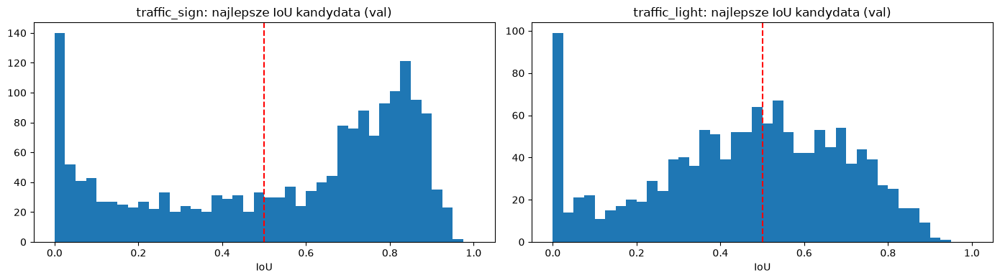

In [13]:
IOU_BINS = [0, 0.1, 0.3, 0.5, 1.01]
IOU_LABELS = ["< 0,1", "0,1-0,3", "0,3-0,5", "≥ 0,5"]


def best_iou_per_gt(data, cands, cls):
    rows = []
    for name, item in data.items():
        gt = gt_boxes(item, cls)
        if len(gt) == 0:
            continue
        boxes = cands[name][cls]
        boxes = boxes[filter_mask(boxes, FILTERS[cls])]
        best = iou_matrix(gt, boxes).max(1) if len(boxes) else np.zeros(len(gt))
        for g, iou in zip(gt, best):
            rows.append({"size": np.sqrt(max((g[2] - g[0]) * (g[3] - g[1]), 0)), "best_iou": iou})
    result = pd.DataFrame(rows)
    result["przedział IoU"] = pd.cut(result.best_iou, IOU_BINS, labels=IOU_LABELS, right=False)
    result["rozmiar"] = pd.cut(result["size"], [0, 8, 16, 32, 64, 1000])
    return result


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, cls in zip(axes, CLASSES):
    best = best_iou_per_gt(val, CANDS["val"], cls)
    print(cls)
    display(pd.crosstab(best["rozmiar"], best["przedział IoU"], normalize="index", margins=True).round(3))
    ax.hist(best.best_iou, bins=40, range=(0, 1))
    ax.axvline(0.5, color="r", ls="--")
    ax.set_title(f"{cls}: najlepsze IoU kandydata (val)")
    ax.set_xlabel("IoU")
plt.tight_layout()
plt.show()

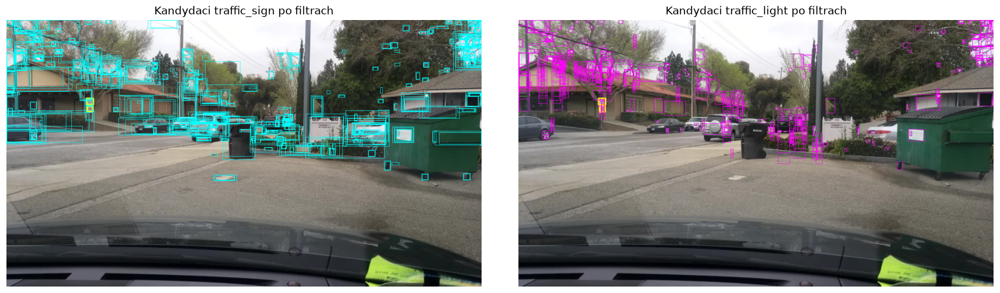

In [14]:
name = pick(val, 1)[0]
img = read_rgb(name)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, cls, color in zip(axes, CLASSES, [(0, 255, 255), (255, 0, 255)]):
    vis = draw_gt(img, ALL[name], 3)
    boxes = CANDS["val"][name][cls]
    for x1, y1, x2, y2 in boxes[filter_mask(boxes, FILTERS[cls])].astype(int):
        cv2.rectangle(vis, (x1, y1), (x2, y2), color, 1)
    ax.imshow(vis)
    ax.axis("off")
    ax.set_title(f"Kandydaci {cls} po filtrach")
plt.tight_layout()
plt.show()

## 5. Cechy i klasyfikator

Każdy kandydat (z marginesem 10% kontekstu) opisywany jest wektorem cech:
- HOG z wycinka 32×32 w skali szarości po wyrównaniu histogramu - 324 cechy,
- histogram barwy ważony nasyceniem i jasnością oraz średnie S i V - 14 cech,
- geometria ramki: log szerokości, log wysokości, log proporcji, położenie pionowe - 4 cechy.

Porównano dwa klasyfikatory: liniowy SVM (ze standaryzacją cech) i gradient boosting na drzewach. Oba z wagami klas, ponieważ kandydatów tła jest znacznie więcej niż obiektów. Wybierany jest model z wyższym F1 w walidacji krzyżowej na próbkach treningowych.

Próbki pozytywne: ramki GT (po filtrach) z dwiema losowo przesuniętymi kopiami oraz kandydaci z IoU ≥ 0,5. Próbki negatywne: losowi kandydaci z IoU < 0,3 (do 40 na obraz).

**Hard negative mining:** po pierwszym treningu oceniani są wszyscy kandydaci z obrazów treningowych. Najwyżej ocenione fałszywe ramki (do 20 na obraz) są dodawane do zbioru negatywów i model jest trenowany ponownie.

**Regresja ramki:** diagnostyka w pkt 4.2 pokazała, że wiele obiektów ma kandydata z IoU 0,3-0,5, czyli trafionego, ale z niedokładną ramką. Na tych samych cechach trenowane są cztery regresory (gradient boosting), które przewidują przesunięcie środka ramki (względem jej szerokości i wysokości) oraz logarytm zmiany szerokości i wysokości. Dane treningowe: kandydaci z IoU ≥ 0,3 do obiektu GT (do 50 na obraz) oraz przesunięte kopie ramek GT. Podczas detekcji wszystkie ramki są korygowane przed NMS.

In [15]:
PATCH = 32
HOG = cv2.HOGDescriptor((PATCH, PATCH), (16, 16), (8, 8), (8, 8), 9)
N_FEATURES = 324 + 14 + 4


def crop(img, box, margin=0.1):
    H, W = img.shape[:2]
    x1, y1, x2, y2 = box
    mw, mh = margin * (x2 - x1), margin * (y2 - y1)
    x1, y1 = int(max(0, x1 - mw)), int(max(0, y1 - mh))
    x2, y2 = int(min(W, np.ceil(x2 + mw))), int(min(H, np.ceil(y2 + mh)))
    return img[y1:max(y2, y1 + 1), x1:max(x2, x1 + 1)]


def features(img, boxes):
    H = img.shape[0]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    boxes = np.asarray(boxes, np.float32).reshape(-1, 4)
    X = np.zeros((len(boxes), N_FEATURES), np.float32)

    for i, box in enumerate(boxes):
        patch = cv2.resize(crop(gray, box), (PATCH, PATCH), interpolation=cv2.INTER_AREA)
        X[i, :324] = HOG.compute(cv2.equalizeHist(patch)).ravel()

        small = cv2.resize(crop(hsv, box), (8, 8), interpolation=cv2.INTER_AREA)
        hue, sat, val_ = [small[..., c].ravel().astype(np.float32) for c in range(3)]
        weights = sat * val_ / 255 ** 2
        X[i, 324:336] = np.bincount((hue // 15).astype(int).clip(0, 11), weights, 12) / 64
        X[i, 336] = sat.mean() / 255
        X[i, 337] = val_.mean() / 255

    w = boxes[:, 2] - boxes[:, 0]
    h = boxes[:, 3] - boxes[:, 1]
    X[:, 338] = np.log(w)
    X[:, 339] = np.log(h)
    X[:, 340] = np.log(h / w)
    X[:, 341] = (boxes[:, 1] + boxes[:, 3]) / 2 / H
    return X


def jitter(box, rng, n=2, scale=0.1):
    w, h = box[2] - box[0], box[3] - box[1]
    shifts = rng.uniform(-scale, scale, (n, 4)) * [w, h, w, h]
    return (box + shifts).astype(np.float32)


def training_set(cls, data, cands, neg_per_img=40):
    rng = np.random.default_rng(SEED)
    X, y = [], []
    for name, item in tqdm(data.items(), desc=f"próbki {cls}"):
        gt_all = gt_boxes(item, cls)
        gt = gt_all[filter_mask(gt_all, FILTERS[cls])]
        boxes = cands[name][cls]
        boxes = boxes[filter_mask(boxes, FILTERS[cls])]
        best_iou = iou_matrix(boxes, gt_all).max(1) if len(gt_all) else np.zeros(len(boxes))

        positives = [boxes[best_iou >= 0.5], gt] + [jitter(g, rng) for g in gt]
        positives = np.concatenate(positives).reshape(-1, 4)
        negatives = boxes[best_iou < 0.3]
        if len(negatives) > neg_per_img:
            negatives = negatives[rng.choice(len(negatives), neg_per_img, replace=False)]
        if len(positives) + len(negatives) == 0:
            continue

        img = cv2.imread(item["img_path"])
        X.append(features(img, np.concatenate([positives, negatives])))
        y.append(np.r_[np.ones(len(positives)), np.zeros(len(negatives))])
    return np.concatenate(X), np.concatenate(y)


def make_model(name):
    if name == "liniowy SVM":
        return make_pipeline(StandardScaler(), LinearSVC(C=0.01, class_weight="balanced", max_iter=5000))
    return HistGradientBoostingClassifier(max_iter=300, max_leaf_nodes=31, class_weight="balanced",
                                          random_state=SEED)


def choose_model(X, y):
    scores = {}
    for name in ("liniowy SVM", "gradient boosting"):
        scores[name] = cross_val_score(make_model(name), X, y, cv=3, scoring="f1").mean()
        print(f"{name}: F1 (walidacja krzyżowa) = {scores[name]:.3f}")
    best = max(scores, key=scores.get)
    print("wybrany model:", best)
    return best


def hard_negatives(cls, data, cands, model, per_img=20):
    X = []
    for name, item in tqdm(data.items(), desc=f"hard negatives {cls}"):
        boxes = cands[name][cls]
        boxes = boxes[filter_mask(boxes, FILTERS[cls])]
        gt = gt_boxes(item, cls)
        if len(gt):
            boxes = boxes[iou_matrix(boxes, gt).max(1) < 0.3]
        if len(boxes) == 0:
            continue
        F = features(cv2.imread(item["img_path"]), boxes)
        top = np.argsort(-model.decision_function(F))[:per_img]
        X.append(F[top])
    return np.concatenate(X)


def train_detector(cls):
    X, y = load_or_compute(f"train_{cls}", training_set, cls, train, CANDS["train"])
    print(f"próbki: {len(y)}, w tym pozytywne: {int(y.sum())}")
    model_name = choose_model(X, y)
    model = make_model(model_name).fit(X, y)

    X_hard = load_or_compute(f"hard_{cls}_{model_name}", hard_negatives, cls, train, CANDS["train"], model)
    print("dodane trudne negatywy:", len(X_hard))
    X = np.concatenate([X, X_hard])
    y = np.r_[y, np.zeros(len(X_hard))]
    return make_model(model_name).fit(X, y)


def regression_targets(boxes, gt):
    """Przesunięcie środka (względem rozmiaru ramki) i logarytm zmiany szerokości i wysokości."""
    w, h = boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1]
    gw, gh = gt[:, 2] - gt[:, 0], gt[:, 3] - gt[:, 1]
    dx = ((gt[:, 0] + gt[:, 2]) - (boxes[:, 0] + boxes[:, 2])) / 2 / w
    dy = ((gt[:, 1] + gt[:, 3]) - (boxes[:, 1] + boxes[:, 3])) / 2 / h
    return np.c_[dx, dy, np.log(gw / w), np.log(gh / h)]


def apply_regression(boxes, targets, shape):
    w, h = boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1]
    cx = (boxes[:, 0] + boxes[:, 2]) / 2 + targets[:, 0] * w
    cy = (boxes[:, 1] + boxes[:, 3]) / 2 + targets[:, 1] * h
    new_w = w * np.exp(np.clip(targets[:, 2], -1, 1))
    new_h = h * np.exp(np.clip(targets[:, 3], -1, 1))
    H, W = shape[:2]
    result = np.c_[cx - new_w / 2, cy - new_h / 2, cx + new_w / 2, cy + new_h / 2]
    result[:, [0, 2]] = result[:, [0, 2]].clip(0, W - 1)
    result[:, [1, 3]] = result[:, [1, 3]].clip(0, H - 1)
    return result.astype(np.float32)


def regression_set(cls, data, cands, max_per_img=50):
    rng = np.random.default_rng(SEED)
    X, T = [], []
    for name, item in tqdm(data.items(), desc=f"próbki regresji {cls}"):
        gt = gt_boxes(item, cls)
        gt = gt[filter_mask(gt, FILTERS[cls])]
        if len(gt) == 0:
            continue
        boxes = cands[name][cls]
        boxes = boxes[filter_mask(boxes, FILTERS[cls])]

        pairs_boxes, pairs_gt = [], []
        if len(boxes):
            ious = iou_matrix(boxes, gt)
            near = np.where(ious.max(1) >= 0.3)[0]
            if len(near) > max_per_img:
                near = rng.choice(near, max_per_img, replace=False)
            pairs_boxes.append(boxes[near])
            pairs_gt.append(gt[ious[near].argmax(1)])
        for g in gt:
            pairs_boxes.append(jitter(g, rng))
            pairs_gt.append(np.repeat(g[None], 2, axis=0))

        P, G = np.concatenate(pairs_boxes), np.concatenate(pairs_gt)
        valid = (P[:, 2] - P[:, 0] >= 2) & (P[:, 3] - P[:, 1] >= 2)
        P, G = P[valid], G[valid]
        X.append(features(cv2.imread(item["img_path"]), P))
        T.append(regression_targets(P, G))
    return np.concatenate(X), np.concatenate(T)


def train_box_regressor(cls):
    X, T = load_or_compute(f"regression_{cls}", regression_set, cls, train, CANDS["train"])
    print(f"próbki regresji ramki: {len(T)}")
    regressors = []
    for k in range(4):
        reg = HistGradientBoostingRegressor(max_iter=200, max_leaf_nodes=31, random_state=SEED)
        regressors.append(reg.fit(X, T[:, k]))
    return regressors


def predict_regression(regressors, X):
    return np.stack([reg.predict(X) for reg in regressors], axis=1)


def score_candidates(cls, data, cands, model, regressors):
    """Wynik klasyfikatora, ramki po regresji i maska filtrów dla wszystkich kandydatów."""
    scored = {}
    for name, item in tqdm(data.items(), desc=f"ocena kandydatów {cls}"):
        boxes = cands[name][cls]
        scores = np.zeros(0)
        boxes_reg = boxes
        if len(boxes):
            img = cv2.imread(item["img_path"])
            X = features(img, boxes)
            scores = model.decision_function(X)
            boxes_reg = apply_regression(boxes, predict_regression(regressors, X), img.shape)
        scored[name] = {"boxes": boxes, "boxes_reg": boxes_reg, "scores": scores,
                        "mask": filter_mask(boxes, FILTERS[cls])}
    return scored


def postprocess(scored, thr, nms_iou=0.3, use_filter=True, use_regression=True):
    preds = {}
    for name, d in scored.items():
        keep = d["scores"] >= thr
        if use_filter:
            keep &= d["mask"]
        all_boxes = d["boxes_reg"] if use_regression else d["boxes"]
        boxes, scores = all_boxes[keep], d["scores"][keep]
        idx = nms(boxes, scores, nms_iou)
        preds[name] = {"boxes": boxes[idx], "scores": scores[idx]}
    return preds


def tune(scored, data, cls):
    """Dobór progu pewności i progu NMS na zbiorze walidacyjnym (maksymalne F1)."""
    all_scores = np.concatenate([d["scores"][d["mask"]] for d in scored.values()])
    quantiles = 1 - np.logspace(-4, -0.3, 30)          # od 0,9999 do ok. 0,5
    thresholds = np.unique(np.quantile(all_scores, quantiles))
    rows = []
    for nms_iou in (0.2, 0.3, 0.5):
        for thr in thresholds:
            r = evaluate(postprocess(scored, thr, nms_iou), data, cls)
            rows.append({"thr": thr, "nms_iou": nms_iou, **{k: r[k] for k in METRICS}})
    grid = pd.DataFrame(rows)
    best = grid.loc[grid.F1.idxmax()]
    return {"thr": float(best.thr), "nms_iou": float(best.nms_iou)}, grid


def plot_tuning(grid, params, cls):
    g = grid[grid.nms_iou == params["nms_iou"]].sort_values("thr")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for metric in ("precision", "recall", "F1"):
        axes[0].plot(g.thr, g[metric], label=metric)
    axes[0].axvline(params["thr"], color="k", ls="--")
    axes[0].set_xlabel("próg wyniku klasyfikatora")
    axes[0].set_title(f"{cls} - val, NMS IoU = {params['nms_iou']}")
    axes[0].legend()
    axes[1].plot(g.recall, g.precision, marker=".")
    axes[1].set_xlabel("recall")
    axes[1].set_ylabel("precision")
    axes[1].set_title("Krzywa P-R (val)")
    plt.tight_layout()
    plt.show()


def proposal_recall_scored(scored, data, cls, key):
    """Odsetek obiektów GT pokrytych z IoU >= 0,5 przez kandydata po filtrach (key: "boxes" lub "boxes_reg")."""
    hits = total = 0
    for name, item in data.items():
        gt = gt_boxes(item, cls)
        boxes = scored[name][key][scored[name]["mask"]]
        total += len(gt)
        if len(gt) and len(boxes):
            hits += int((iou_matrix(gt, boxes).max(1) >= 0.5).sum())
    return hits / max(total, 1)


def show_val_result(scored, params, cls):
    rows = {}
    for use_regression in (False, True):
        r = evaluate(postprocess(scored, **params, use_regression=use_regression), val, cls)
        key = "boxes_reg" if use_regression else "boxes"
        label = "z regresją ramki" if use_regression else "bez regresji ramki"
        rows[label] = {"recall propozycji": proposal_recall_scored(scored, val, cls, key),
                       **{k: r[k] for k in METRICS}}
    print(f"{cls} - zbiór walidacyjny:")
    display(pd.DataFrame(rows).T.round(3))

## 6. Zadanie 2 - detektor znaków drogowych

próbki traffic_sign:   0%|          | 0/2000 [00:00<?, ?it/s]

próbki: 115047, w tym pozytywne: 35047
liniowy SVM: F1 (walidacja krzyżowa) = 0.671
gradient boosting: F1 (walidacja krzyżowa) = 0.818
wybrany model: gradient boosting


hard negatives traffic_sign:   0%|          | 0/2000 [00:00<?, ?it/s]

dodane trudne negatywy: 40000


próbki regresji traffic_sign:   0%|          | 0/2000 [00:00<?, ?it/s]

próbki regresji ramki: 38839


ocena kandydatów traffic_sign:   0%|          | 0/500 [00:00<?, ?it/s]

parametry: {'thr': 0.9110683105090277, 'nms_iou': 0.2}


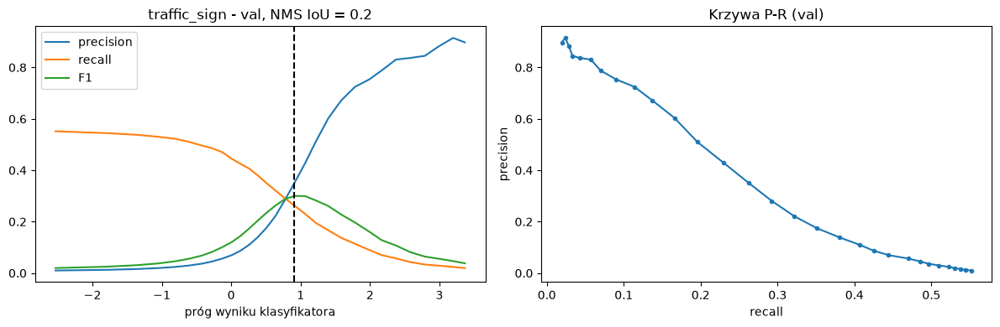

traffic_sign - zbiór walidacyjny:


,recall propozycji,TP,FP,FN,precision,recall,F1
bez regresji ramki,0.616,453.0,918.0,1345.0,0.330,0.252,0.286
z regresją ramki,0.645,472.0,874.0,1326.0,0.351,0.263,0.300


In [16]:
clf_sign = train_detector("traffic_sign")
reg_sign = train_box_regressor("traffic_sign")
scored_sign_val = score_candidates("traffic_sign", val, CANDS["val"], clf_sign, reg_sign)
P_SIGN, grid_sign = tune(scored_sign_val, val, "traffic_sign")
print("parametry:", P_SIGN)
plot_tuning(grid_sign, P_SIGN, "traffic_sign")
show_val_result(scored_sign_val, P_SIGN, "traffic_sign")

## 7. Zadanie 3 - detektor sygnalizatorów i rozpoznawanie koloru

Detekcja przebiega tak samo jak dla znaków, z osobnym klasyfikatorem i własnymi progami.

próbki traffic_light:   0%|          | 0/2000 [00:00<?, ?it/s]

próbki: 100606, w tym pozytywne: 20863
liniowy SVM: F1 (walidacja krzyżowa) = 0.649
gradient boosting: F1 (walidacja krzyżowa) = 0.876
wybrany model: gradient boosting


hard negatives traffic_light:   0%|          | 0/2000 [00:00<?, ?it/s]

dodane trudne negatywy: 39960


próbki regresji traffic_light:   0%|          | 0/2000 [00:00<?, ?it/s]

próbki regresji ramki: 26897


ocena kandydatów traffic_light:   0%|          | 0/500 [00:00<?, ?it/s]

parametry: {'thr': 0.6554823676253677, 'nms_iou': 0.2}


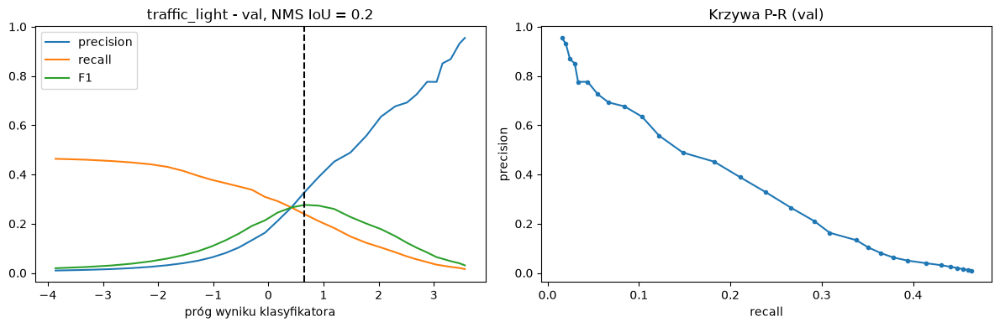

traffic_light - zbiór walidacyjny:


,recall propozycji,TP,FP,FN,precision,recall,F1
bez regresji ramki,0.467,243.0,752.0,1101.0,0.244,0.181,0.208
z regresją ramki,0.629,321.0,658.0,1023.0,0.328,0.239,0.276


In [17]:
clf_light = train_detector("traffic_light")
reg_light = train_box_regressor("traffic_light")
scored_light_val = score_candidates("traffic_light", val, CANDS["val"], clf_light, reg_light)
P_LIGHT, grid_light = tune(scored_light_val, val, "traffic_light")
print("parametry:", P_LIGHT)
plot_tuning(grid_light, P_LIGHT, "traffic_light")
show_val_result(scored_light_val, P_LIGHT, "traffic_light")

### 7.1 Kolor sygnalizatora

Porównano dwa podejścia. Parametry reguł dobrano, a klasyfikator wytrenowano wyłącznie na ramkach GT ze zbiorów train i val.

1. **Reguły HSV.** W ramce wybierane są piksele świecące (S ≥ s_min, V ≥ v_min). Jeżeli stanowią mniej niż `min_frac` powierzchni ramki, wynikiem jest `unknown`. Dla każdego koloru liczone są świecące piksele w jego zakresie barwy: czerwony H < y_lo lub H ≥ 160, żółty y_lo ≤ H < y_hi, zielony 35 ≤ H ≤ 100. Najliczniejszy kolor musi mieć co najmniej `ratio` razy więcej pikseli niż drugi, w przeciwnym razie wynikiem jest `unknown`.
2. **Klasyfikator koloru** (gradient boosting) na cechach wycinka: histogram barwy świecących pikseli, udział świecących pikseli, średnie S i V oraz położenie świecącej plamy wzdłuż dłuższego boku ramki (czerwone światło jest zwykle u góry lub z lewej, zielone u dołu lub z prawej).

Do dalszej części wybierana jest metoda z wyższą accuracy na ramkach GT ze zbioru walidacyjnego.

In [18]:
def color_by_rules(patch_hsv, s_min, v_min, min_frac, y_lo, y_hi, ratio):
    h, s, v = patch_hsv[..., 0], patch_hsv[..., 1], patch_hsv[..., 2]
    lit = (s >= s_min) & (v >= v_min)
    if lit.mean() < min_frac:
        return "unknown"
    hue = h[lit]
    counts = {
        "red": int(((hue < y_lo) | (hue >= 160)).sum()),
        "yellow": int(((hue >= y_lo) & (hue < y_hi)).sum()),
        "green": int(((hue >= 35) & (hue <= 100)).sum()),
    }
    ranked = sorted(counts, key=counts.get, reverse=True)
    first, second = counts[ranked[0]], counts[ranked[1]]
    if first == 0 or first < ratio * second:
        return "unknown"
    return ranked[0]


def lamp_position(v, lit):
    """Położenie świecącej plamy wzdłuż dłuższego boku ramki: 0 - góra/lewo, 1 - dół/prawo."""
    weights = v * lit
    if weights.sum() == 0:
        return 0.5
    h, w = v.shape
    if h >= w:
        coord = np.arange(h)[:, None] / max(h - 1, 1)
    else:
        coord = np.arange(w)[None, :] / max(w - 1, 1)
    return float((weights * coord).sum() / weights.sum())


def color_features(patch_hsv):
    h = patch_hsv[..., 0].astype(int)
    s = patch_hsv[..., 1].astype(float)
    v = patch_hsv[..., 2].astype(float)
    lit = (s >= 70) & (v >= 130)
    hue_hist = np.bincount((h[lit] // 10).clip(0, 17), minlength=18) / max(lit.sum(), 1)
    ph, pw = h.shape
    return np.r_[hue_hist, lit.mean(), s.mean() / 255, v.mean() / 255, (v > 200).mean(),
                 lamp_position(v, lit), ph / max(pw, 1)]


def gt_light_patches(data):
    patches = []
    for item in tqdm(data.values(), desc="wycinki sygnalizatorów"):
        gt, colors = gt_boxes(item, "traffic_light"), gt_colors(item)
        if len(gt) == 0:
            continue
        img = cv2.imread(item["img_path"])
        for box, color in zip(gt, colors):
            if box[2] - box[0] >= 1 and box[3] - box[1] >= 1:
                patches.append((cv2.cvtColor(crop(img, box, 0), cv2.COLOR_BGR2HSV), color))
    return patches


def color_confusion(pairs):
    cm = pd.DataFrame(0, index=pd.Index(COLORS, name="GT"), columns=pd.Index(COLORS, name="pred"))
    for gt_color, pred_color in pairs:
        cm.loc[gt_color, pred_color] += 1
    return cm


patches_train = load_or_compute("color_patches_train", gt_light_patches, train)
patches_val = load_or_compute("color_patches_val", gt_light_patches, val)
y_color_val = np.array([color for _, color in patches_val])

wycinki sygnalizatorów:   0%|          | 0/2000 [00:00<?, ?it/s]

wycinki sygnalizatorów:   0%|          | 0/500 [00:00<?, ?it/s]

parametry reguł: {'s_min': 100.0, 'v_min': 130.0, 'min_frac': 0.01, 'y_lo': 15.0, 'y_hi': 26.0, 'ratio': 1.5}


,s_min,v_min,min_frac,y_lo,y_hi,ratio,accuracy
153,100,130,0.01,15,26,1.5,0.684
81,70,160,0.01,15,26,1.5,0.680
155,100,130,0.01,15,26,3.0,0.680
154,100,130,0.01,15,26,2.0,0.679
152,100,130,0.01,15,26,1.0,0.679


accuracy (GT val): reguły = 0.684, klasyfikator = 0.827
wybrana metoda: klasyfikator


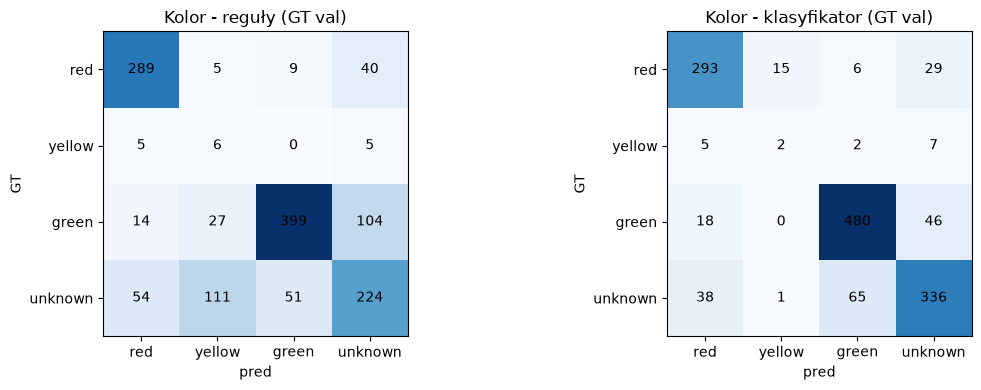

In [19]:
# 1. reguły: przeszukanie siatki parametrów na val
param_grid = itertools.product((70, 100), (100, 130, 160), (0.01, 0.03, 0.06),
                               ((10, 35), (13, 30), (15, 26)), (1.0, 1.5, 2.0, 3.0))
rows = []
for s_min, v_min, min_frac, (y_lo, y_hi), ratio in param_grid:
    params = dict(s_min=s_min, v_min=v_min, min_frac=min_frac, y_lo=y_lo, y_hi=y_hi, ratio=ratio)
    pred = [color_by_rules(p, **params) for p, _ in patches_val]
    rows.append({**params, "accuracy": np.mean(np.array(pred) == y_color_val)})
color_grid = pd.DataFrame(rows).sort_values("accuracy", ascending=False)
P_COLOR = color_grid.iloc[0].drop("accuracy").to_dict()
print("parametry reguł:", P_COLOR)
display(color_grid.head(5).round(3))

# 2. klasyfikator koloru: trening na train, ocena na val
X_color_train = np.array([color_features(p) for p, _ in patches_train])
y_color_train = np.array([color for _, color in patches_train])
X_color_val = np.array([color_features(p) for p, _ in patches_val])
color_clf = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=SEED)
color_clf.fit(X_color_train, y_color_train)

pred_rules = np.array([color_by_rules(p, **P_COLOR) for p, _ in patches_val])
pred_clf = color_clf.predict(X_color_val)
acc_rules = np.mean(pred_rules == y_color_val)
acc_clf = np.mean(pred_clf == y_color_val)
print(f"accuracy (GT val): reguły = {acc_rules:.3f}, klasyfikator = {acc_clf:.3f}")

COLOR_METHOD = "klasyfikator" if acc_clf > acc_rules else "reguły"
print("wybrana metoda:", COLOR_METHOD)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, pred) in zip(axes, [("reguły", pred_rules), ("klasyfikator", pred_clf)]):
    cm = color_confusion(zip(y_color_val, pred))
    ax.imshow(cm.values, cmap="Blues")
    for i in range(len(COLORS)):
        for j in range(len(COLORS)):
            ax.text(j, i, cm.values[i, j], ha="center", va="center")
    ax.set_xticks(range(len(COLORS)), COLORS)
    ax.set_yticks(range(len(COLORS)), COLORS)
    ax.set_xlabel("pred")
    ax.set_ylabel("GT")
    ax.set_title(f"Kolor - {title} (GT val)")
plt.tight_layout()
plt.show()

In [20]:
def classify_color(img, box):
    patch_hsv = cv2.cvtColor(crop(img, box, 0), cv2.COLOR_BGR2HSV)
    if COLOR_METHOD == "klasyfikator":
        return color_clf.predict(color_features(patch_hsv)[None])[0]
    return color_by_rules(patch_hsv, **P_COLOR)


def add_colors(preds, data):
    for name, pred in preds.items():
        img = cv2.imread(data[name]["img_path"])
        pred["colors"] = [classify_color(img, box) for box in pred["boxes"]]
    return preds

## 8. Zadanie 4 - ocena na zbiorze testowym

Wszystkie parametry dobrano na zbiorach train i val. Zbiór testowy wykorzystano jednokrotnie.

Porównano trzy warianty:
- kandydaci bez weryfikacji - wszyscy kandydaci po filtrach i NMS,
- klasyfikator bez filtrów położenia i rozmiaru,
- klasyfikator z filtrami, bez regresji ramki,
- klasyfikator z filtrami i regresją ramki - wariant docelowy.

In [21]:
scored_test = {
    "traffic_sign": score_candidates("traffic_sign", test, CANDS["test"], clf_sign, reg_sign),
    "traffic_light": score_candidates("traffic_light", test, CANDS["test"], clf_light, reg_light),
}
PARAMS = {"traffic_sign": P_SIGN, "traffic_light": P_LIGHT}

comparison = {}
final_preds = {}
for cls in CLASSES:
    scored, params = scored_test[cls], PARAMS[cls]
    variants = {
        "kandydaci bez weryfikacji": postprocess(scored, -np.inf, params["nms_iou"], use_regression=False),
        "klasyfikator bez filtrów": postprocess(scored, params["thr"], params["nms_iou"], use_filter=False,
                                               use_regression=False),
        "klasyfikator + filtry": postprocess(scored, params["thr"], params["nms_iou"], use_regression=False),
        "klasyfikator + filtry + regresja": postprocess(scored, params["thr"], params["nms_iou"]),
    }
    for variant, preds in variants.items():
        r = evaluate(preds, test, cls)
        comparison[(cls, variant)] = {k: r[k] for k in METRICS}
    final_preds[cls] = variants["klasyfikator + filtry + regresja"]

print("Detekcja - zbiór testowy, IoU ≥ 0,5")
display(pd.DataFrame(comparison).T.round(3))

ocena kandydatów traffic_sign:   0%|          | 0/500 [00:00<?, ?it/s]

ocena kandydatów traffic_light:   0%|          | 0/500 [00:00<?, ?it/s]

Detekcja - zbiór testowy, IoU ≥ 0,5


TP        FP      FN  \
traffic_sign  kandydaci bez weryfikacji         859.0  245232.0   818.0   
              klasyfikator bez filtrów          422.0    1068.0  1255.0   
              klasyfikator + filtry             411.0     882.0  1266.0   
              klasyfikator + filtry + regresja  438.0     832.0  1239.0   
traffic_light kandydaci bez weryfikacji         466.0  116513.0   955.0   
              klasyfikator bez filtrów          244.0    5876.0  1177.0   
              klasyfikator + filtry             270.0     974.0  1151.0   
              klasyfikator + filtry + regresja  355.0     855.0  1066.0   

                                                precision  recall     F1  
traffic_sign  kandydaci bez weryfikacji             0.003   0.512  0.007  
              klasyfikator bez filtrów              0.283   0.252  0.266  
              klasyfikator + filtry                 0.318   0.245  0.277  
              klasyfikator + filtry + regresja      0.345   0.261  0.297  
traffic_light kandydaci bez weryfikacji             0.004   0.328  0.008  
              klasyfikator bez filtrów              0.040   0.172  0.065  
              klasyfikator + filtry                 0.217   0.190  0.203  
              klasyfikator + filtry + regresja      0.293   0.250  0.270

In [22]:
PRED_SIGN = final_preds["traffic_sign"]
PRED_LIGHT = add_colors(final_preds["traffic_light"], test)
EVAL = {
    "traffic_sign": evaluate(PRED_SIGN, test, "traffic_sign"),
    "traffic_light": evaluate(PRED_LIGHT, test, "traffic_light"),
}

results = pd.DataFrame({cls: {k: EVAL[cls][k] for k in METRICS} for cls in CLASSES}).T
print("Wariant docelowy - zbiór testowy:")
display(results.round(3))

cm = color_confusion(EVAL["traffic_light"]["colors"])
n_tp = cm.values.sum()
print(f"Kolor na poprawnie zlokalizowanych sygnalizatorach (n = {n_tp}): "
      f"accuracy = {np.trace(cm.values) / max(n_tp, 1):.3f}")
display(cm)

Wariant docelowy - zbiór testowy:


,TP,FP,FN,precision,recall,F1
traffic_sign,438.0,832.0,1239.0,0.345,0.261,0.297
traffic_light,355.0,855.0,1066.0,0.293,0.250,0.270


Kolor na poprawnie zlokalizowanych sygnalizatorach (n = 355): accuracy = 0.910


pred,red,yellow,green,unknown
GT,,,,
red,68,2,0,1
yellow,5,0,0,2
green,2,0,229,7
unknown,4,1,8,26


### Zapis predykcji

Predykcje dla zbioru testowego zapisywane są do `predictions_test_lab2A.json` (do porównania z laboratorium 2B), lista obrazów testowych do `test_images.json`, a tabela wyników do `results_test_lab2A.csv`.

In [23]:
def to_label(category, box, score):
    x1, y1, x2, y2 = map(float, box)
    return {"category": category, "score": float(score), "box2d": {"x1": x1, "y1": y1, "x2": x2, "y2": y2}}


output = []
for name in sorted(test):
    labels = []
    for box, score in zip(PRED_SIGN[name]["boxes"], PRED_SIGN[name]["scores"]):
        labels.append(to_label("traffic_sign", box, score))
    light = PRED_LIGHT[name]
    for box, score, color in zip(light["boxes"], light["scores"], light["colors"]):
        labels.append(to_label(f"traffic_light_{color}", box, score))
    output.append({"name": name, "labels": labels})

with open("predictions_test_lab2A.json", "w") as f:
    json.dump(output, f, indent=1)
with open("test_images.json", "w") as f:
    json.dump(sorted(test), f)
results.to_csv("results_test_lab2A.csv")
print("Zapisano predykcje dla", len(output), "obrazów testowych")

Zapisano predykcje dla 500 obrazów testowych


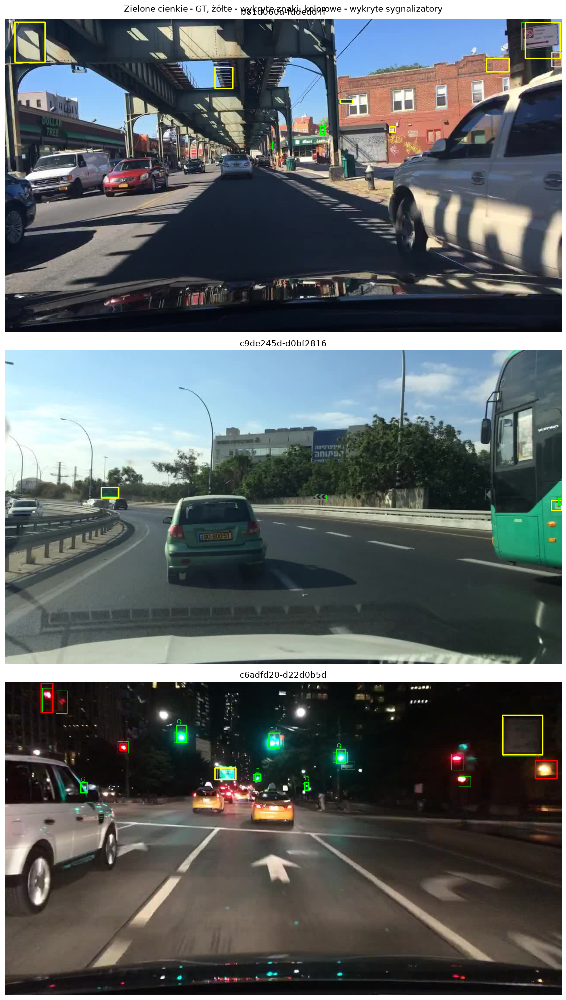

In [24]:
def show_predictions(names, title):
    fig, axes = plt.subplots(len(names), 1, figsize=(12, 6.8 * len(names)), squeeze=False)
    for ax, name in zip(axes.ravel(), names):
        vis = read_rgb(name)
        for b in ALL[name]["boxes"]:
            x1, y1, x2, y2 = map(int, b["box"])
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 1)
        for x1, y1, x2, y2 in PRED_SIGN[name]["boxes"].astype(int):
            cv2.rectangle(vis, (x1, y1), (x2, y2), DRAW_COLORS["traffic_sign"], 2)
        for (x1, y1, x2, y2), color in zip(PRED_LIGHT[name]["boxes"].astype(int), PRED_LIGHT[name]["colors"]):
            cv2.rectangle(vis, (x1, y1), (x2, y2), DRAW_COLORS[color], 2)
            cv2.putText(vis, color[0].upper(), (x1, y1 - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.5, DRAW_COLORS[color], 1)
        ax.imshow(vis)
        ax.axis("off")
        ax.set_title(name)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_predictions(pick(test, 3), "Zielone cienkie - GT, żółte - wykryte znaki, kolorowe - wykryte sygnalizatory")

### Czas działania

Średni czas przetworzenia jednego obrazu przez cały detektor (kandydaci, cechy, klasyfikator, regresja ramki, NMS, kolor), mierzony na obrazach testowych bez czasu wczytania pliku. Wynik zapisywany jest do `fps_lab2A.json`, aby porównać go z laboratorium 2B.

In [25]:
import time


def detect_one_class(img, candidates, cls, clf, regressors):
    boxes = candidates[cls]
    if len(boxes) == 0:
        return np.zeros((0, 4), np.float32), np.zeros(0)
    X = features(img, boxes)
    scores = clf.decision_function(X)
    boxes_reg = apply_regression(boxes, predict_regression(regressors, X), img.shape)
    keep = (scores >= PARAMS[cls]["thr"]) & filter_mask(boxes, FILTERS[cls])
    boxes, scores = boxes_reg[keep], scores[keep]
    idx = nms(boxes, scores, PARAMS[cls]["nms_iou"])
    return boxes[idx], scores[idx]


def detect_image(img):
    candidates = generate_candidates(img)
    signs = detect_one_class(img, candidates, "traffic_sign", clf_sign, reg_sign)
    lights = detect_one_class(img, candidates, "traffic_light", clf_light, reg_light)
    colors = [classify_color(img, box) for box in lights[0]]
    return signs, lights, colors


N_TIMING = 100
timing_images = [cv2.imread(test[name]["img_path"]) for name in sorted(test)[:N_TIMING]]
start = time.perf_counter()
for img in timing_images:
    detect_image(img)
seconds_per_image = (time.perf_counter() - start) / len(timing_images)

timing = {"fps": 1 / seconds_per_image, "seconds_per_image": seconds_per_image,
          "n_images": len(timing_images), "device": "CPU"}
with open("fps_lab2A.json", "w") as f:
    json.dump(timing, f, indent=1)
print(f"średni czas: {seconds_per_image:.2f} s / obraz, czyli {timing['fps']:.2f} fps (CPU, {len(timing_images)} obrazów)")

średni czas: 2.00 s / obraz, czyli 0.50 fps (CPU, 100 obrazów)


## 9. Zadanie 5 - analiza błędów

False positives: predykcje z najwyższym wynikiem klasyfikatora, które nie pasują do żadnego obiektu GT. False negatives: losowe niewykryte obiekty GT o rozmiarze powyżej mediany.

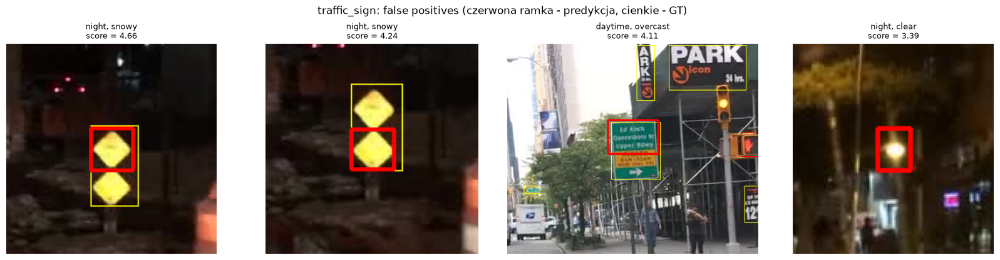

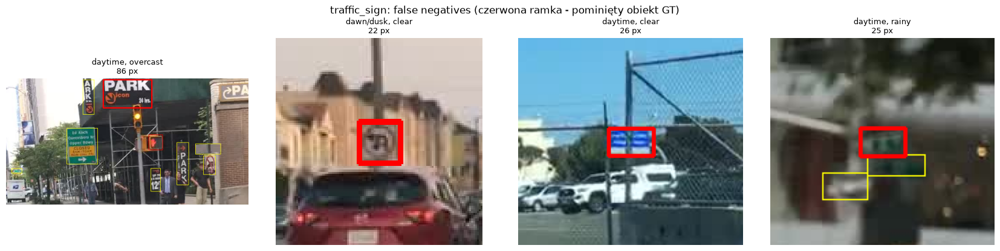

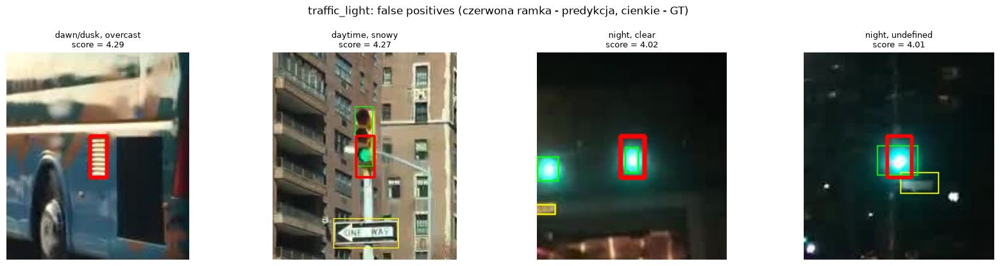

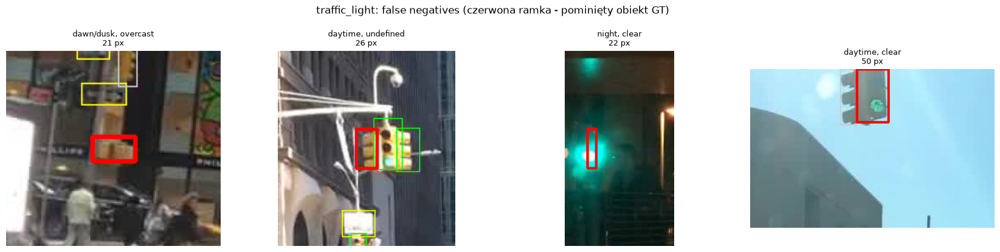

In [26]:
def show_errors(examples, title, box_color=(255, 0, 0)):
    """examples: lista (nazwa obrazu, ramka, podpis)."""
    if not examples:
        print("Brak przykładów:", title)
        return
    fig, axes = plt.subplots(1, len(examples), figsize=(4.2 * len(examples), 4.2), squeeze=False)
    for ax, (name, box, caption) in zip(axes.ravel(), examples):
        vis = draw_gt(read_rgb(name), ALL[name], 1)
        x1, y1, x2, y2 = map(int, box)
        cv2.rectangle(vis, (x1, y1), (x2, y2), box_color, 2)
        m = int(max(40, 2 * max(x2 - x1, y2 - y1)))
        ax.imshow(vis[max(0, y1 - m):y2 + m, max(0, x1 - m):x2 + m])
        attrs = ALL[name]["attrs"]
        ax.set_title(f"{attrs.get('timeofday')}, {attrs.get('weather')}\n{caption}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def box_size(box):
    return np.sqrt(max((box[2] - box[0]) * (box[3] - box[1]), 0))


rng_errors = random.Random(SEED)
for cls in CLASSES:
    r = EVAL[cls]
    top_fp = sorted(r["fp"], key=lambda e: -e[2])[:4]
    fp_examples = [(name, box, f"score = {score:.2f}") for name, box, score in top_fp]

    median_size = r["gt"]["size"].median() if len(r["gt"]) else 0
    large_fn = [(name, box) for name, box in r["fn"] if box_size(box) >= median_size]
    sampled_fn = rng_errors.sample(large_fn, min(4, len(large_fn)))
    fn_examples = [(name, box, f"{box_size(box):.0f} px") for name, box in sampled_fn]

    show_errors(fp_examples, f"{cls}: false positives (czerwona ramka - predykcja, cienkie - GT)")
    show_errors(fn_examples, f"{cls}: false negatives (czerwona ramka - pominięty obiekt GT)")

traffic_sign


liczba  recall
rozmiar [px] (0, 8]          18   0.000
             (8, 16]        452   0.106
             (16, 32]       756   0.284
             (32, 64]       353   0.408
             (64, 1000]      98   0.316
pora dnia    dawn/dusk      142   0.204
             daytime        902   0.266
             night          629   0.269
             undefined        4   0.000

traffic_light


liczba  recall
rozmiar [px] (0, 8]          34   0.000
             (8, 16]        621   0.233
             (16, 32]       568   0.287
             (32, 64]       187   0.246
             (64, 1000]      11   0.091
pora dnia    dawn/dusk      151   0.172
             daytime        597   0.193
             night          673   0.318

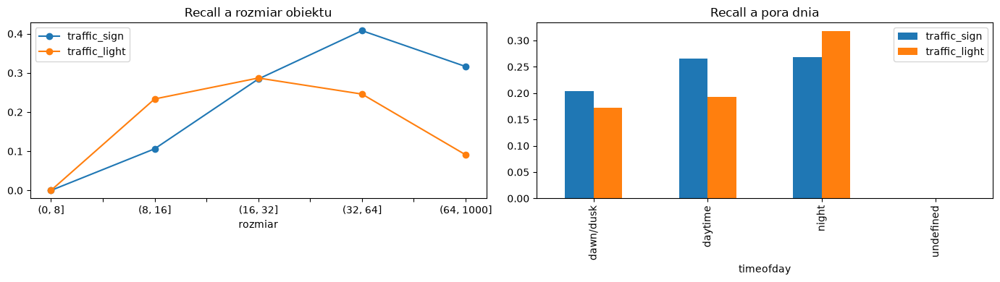

In [27]:
recall_by_size = {}
recall_by_time = {}
for cls in CLASSES:
    gt = EVAL[cls]["gt"].copy()
    gt["rozmiar"] = pd.cut(gt["size"], bins=[0, 8, 16, 32, 64, 1000])
    print(cls)
    by_size = gt.groupby("rozmiar", observed=True)["found"].agg(["count", "mean"])
    by_time = gt.groupby("timeofday")["found"].agg(["count", "mean"])
    display(pd.concat([by_size, by_time], keys=["rozmiar [px]", "pora dnia"])
            .rename(columns={"count": "liczba", "mean": "recall"}).round(3))
    recall_by_size[cls] = by_size["mean"]
    recall_by_time[cls] = by_time["mean"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.DataFrame(recall_by_size).plot(ax=axes[0], marker="o", title="Recall a rozmiar obiektu")
pd.DataFrame(recall_by_time).plot.bar(ax=axes[1], title="Recall a pora dnia")
plt.tight_layout()
plt.show()

### Przyczyny błędów i możliwe ulepszenia

**Znaki - false positives:**
- Przykłady 1-2: dwa znaki jeden nad drugim mają w etykiecie jedną wspólną ramkę, a detektor znajduje każdy znak osobno. IoU jest wtedy mniejsze niż 0,5, więc wykrycie liczy się jako FP, a obiekt z etykiety jako FN.
- Przykład 3: ramka obejmuje tylko górną część tablicy kierunkowej, a w etykiecie zaznaczona jest cała tablica.
- Przykład 4: w nocy latarnia wygląda podobnie do znaku - jest okrągła i jasna.

**Znaki - false negatives:**
- Przykład 1: tablica parkingu jest oznaczona jako znak drogowy, ale wygląda zupełnie inaczej niż typowe znaki.
- Przykład 2: znak jest mały (22 px) i wyblakły, a o zmierzchu ma mało koloru, więc maski HSV go nie wykrywają.
- Przykład 3: tablice z nazwą ulicy są widoczne przez siatkę ogrodzenia, przez co cechy HOG są zakłócone.
- Przykład 4: obraz jest rozmyty przez deszcz i krawędzie tablicy są słabo widoczne.

**Sygnalizatory - false positives:**
- Przykład 1: kratka wentylacyjna autobusu ma podobny kształt do obudowy sygnalizatora.
- Przykład 2: ramka obejmuje tylko dolną część obudowy z zapaloną lampą.
- Przykład 3: wykryta lampa świeci, ale nie ma ramki w etykietach - prawdopodobnie brakuje adnotacji.
- Przykład 4: w nocy ramka w etykiecie obejmuje całą poświatę wokół lampy, a detektor zaznacza tylko jasny środek.

**Sygnalizatory - false negatives:**
- Przykłady 1-2: sygnalizatory są widoczne z boku lub od tyłu i nie widać zapalonego światła, a od niego zaczyna się szukanie kandydatów. W przykładzie 2 dodatkowo kilka sygnalizatorów nachodzi na siebie.
- Przykład 3: w nocy środek lampy jest prawie biały (mało koloru), a wąska ramka z etykiety nie pasuje do kandydatów wyznaczonych z poświaty.
- Przykład 4: ciemna obudowa na tle jasnego nieba i słabo widoczna lampa. Pasuje to do tego, że w dzień recall jest niższy niż w nocy (0,19 wobec 0,32).

**Podsumowanie:** część błędów wynika ze sposobu oznaczenia danych, a nie z działania detektora: kilka znaków w jednej ramce, tablice reklamowe jako znaki, brakujące ramki, inna szerokość ramek w nocy. Przy progu IoU ≥ 0,5 nawet małe przesunięcie ramki daje jednocześnie FP i FN. Pozostałe błędy dotyczą głównie małych obiektów, słabego kontrastu i sygnalizatorów bez widocznego światła.

**Możliwe ulepszenia:**
- szukanie kandydatów na sygnalizatory także bez świecącej lampy, np. jako ciemne prostokąty o proporcjach obudowy,
- osobne progi HSV dla nocy,
- łączenie wykrytych znaków ułożonych jeden nad drugim,
- kolejne rundy hard negative mining,
- dodanie informacji o otoczeniu obiektu (np. słup pod znakiem),
- osobne podejście do bardzo małych obiektów.

## Wnioski

- Detektor działa w dwóch krokach. Najpierw wyszukuje kandydatów (maski HSV, morfologia, MSER, hipotezy obudowy sygnalizatora), potem klasyfikator ocenia, czy kandydat jest znakiem lub sygnalizatorem. Na końcu ramki są poprawiane regresją i filtrowane przez NMS.
- Na zbiorze testowym uzyskano F1 = 0,297 dla znaków (precision 0,345, recall 0,261) i F1 = 0,270 dla sygnalizatorów (precision 0,293, recall 0,250). Kolor poprawnie wykrytych sygnalizatorów rozpoznano z accuracy 0,910.
- Najwięcej dały:
  - filtry położenia i rozmiaru - dla sygnalizatorów liczba FP spadła z 5876 do 974,
  - klasyfikator - bez niego F1 wynosiło ok. 0,01,
  - regresja ramki - F1 wzrosło o 0,02 dla znaków i o 0,07 dla sygnalizatorów.
- Gradient boosting działał lepiej niż liniowy SVM (F1 w walidacji krzyżowej 0,82 wobec 0,67 dla znaków). Klasyfikator koloru był lepszy od reguł HSV (accuracy na zbiorze walidacyjnym 0,83 wobec 0,68).
- Zalety: brak sieci neuronowych, każdy krok można sprawdzić osobno i łatwo znaleźć, gdzie powstają błędy.
- Ograniczenia: słabe wykrywanie małych obiektów, gorsze wyniki w dzień dla sygnalizatorów, dużo kandydatów i długi czas obliczeń. Nawet idealny klasyfikator nie przekroczyłby recallu ok. 0,65, bo dla części obiektów nie ma dobrego kandydata.
- Wyniki są niskie, czego można się było spodziewać po metodach klasycznych na zbiorze z tak małymi obiektami. Posłużą do porównania z sieciami neuronowymi w laboratorium 2B.